# [LAB-06] 데이터 시각화

## 4. Histogram

### #01 준비작업

1. 라이브러리 참조

In [11]:
from jussam import load_data
from helpers import *
import seaborn as sb
import numpy as np

2. 데이터 가져오기

In [12]:
origin = load_data('employee_data_40')
origin.head()

📚 어느 기업의 직원 40명을 대상으로 성별과 결혼상태, 나이, 최종학력, 월수입을 조사한 가상의 데이터(인덱스, 메타데이터 없음)


,성별,결혼상태,나이,최종학력,월수입
0,남자,기혼,21,대학교,60
1,남자,기혼,22,대학원,100
2,남자,기혼,33,대학교,200
3,여자,미혼,33,대학교,120
4,남자,미혼,28,대학교,70


### #02 Histogram 시각화 하기

1. 기본 사용 방법

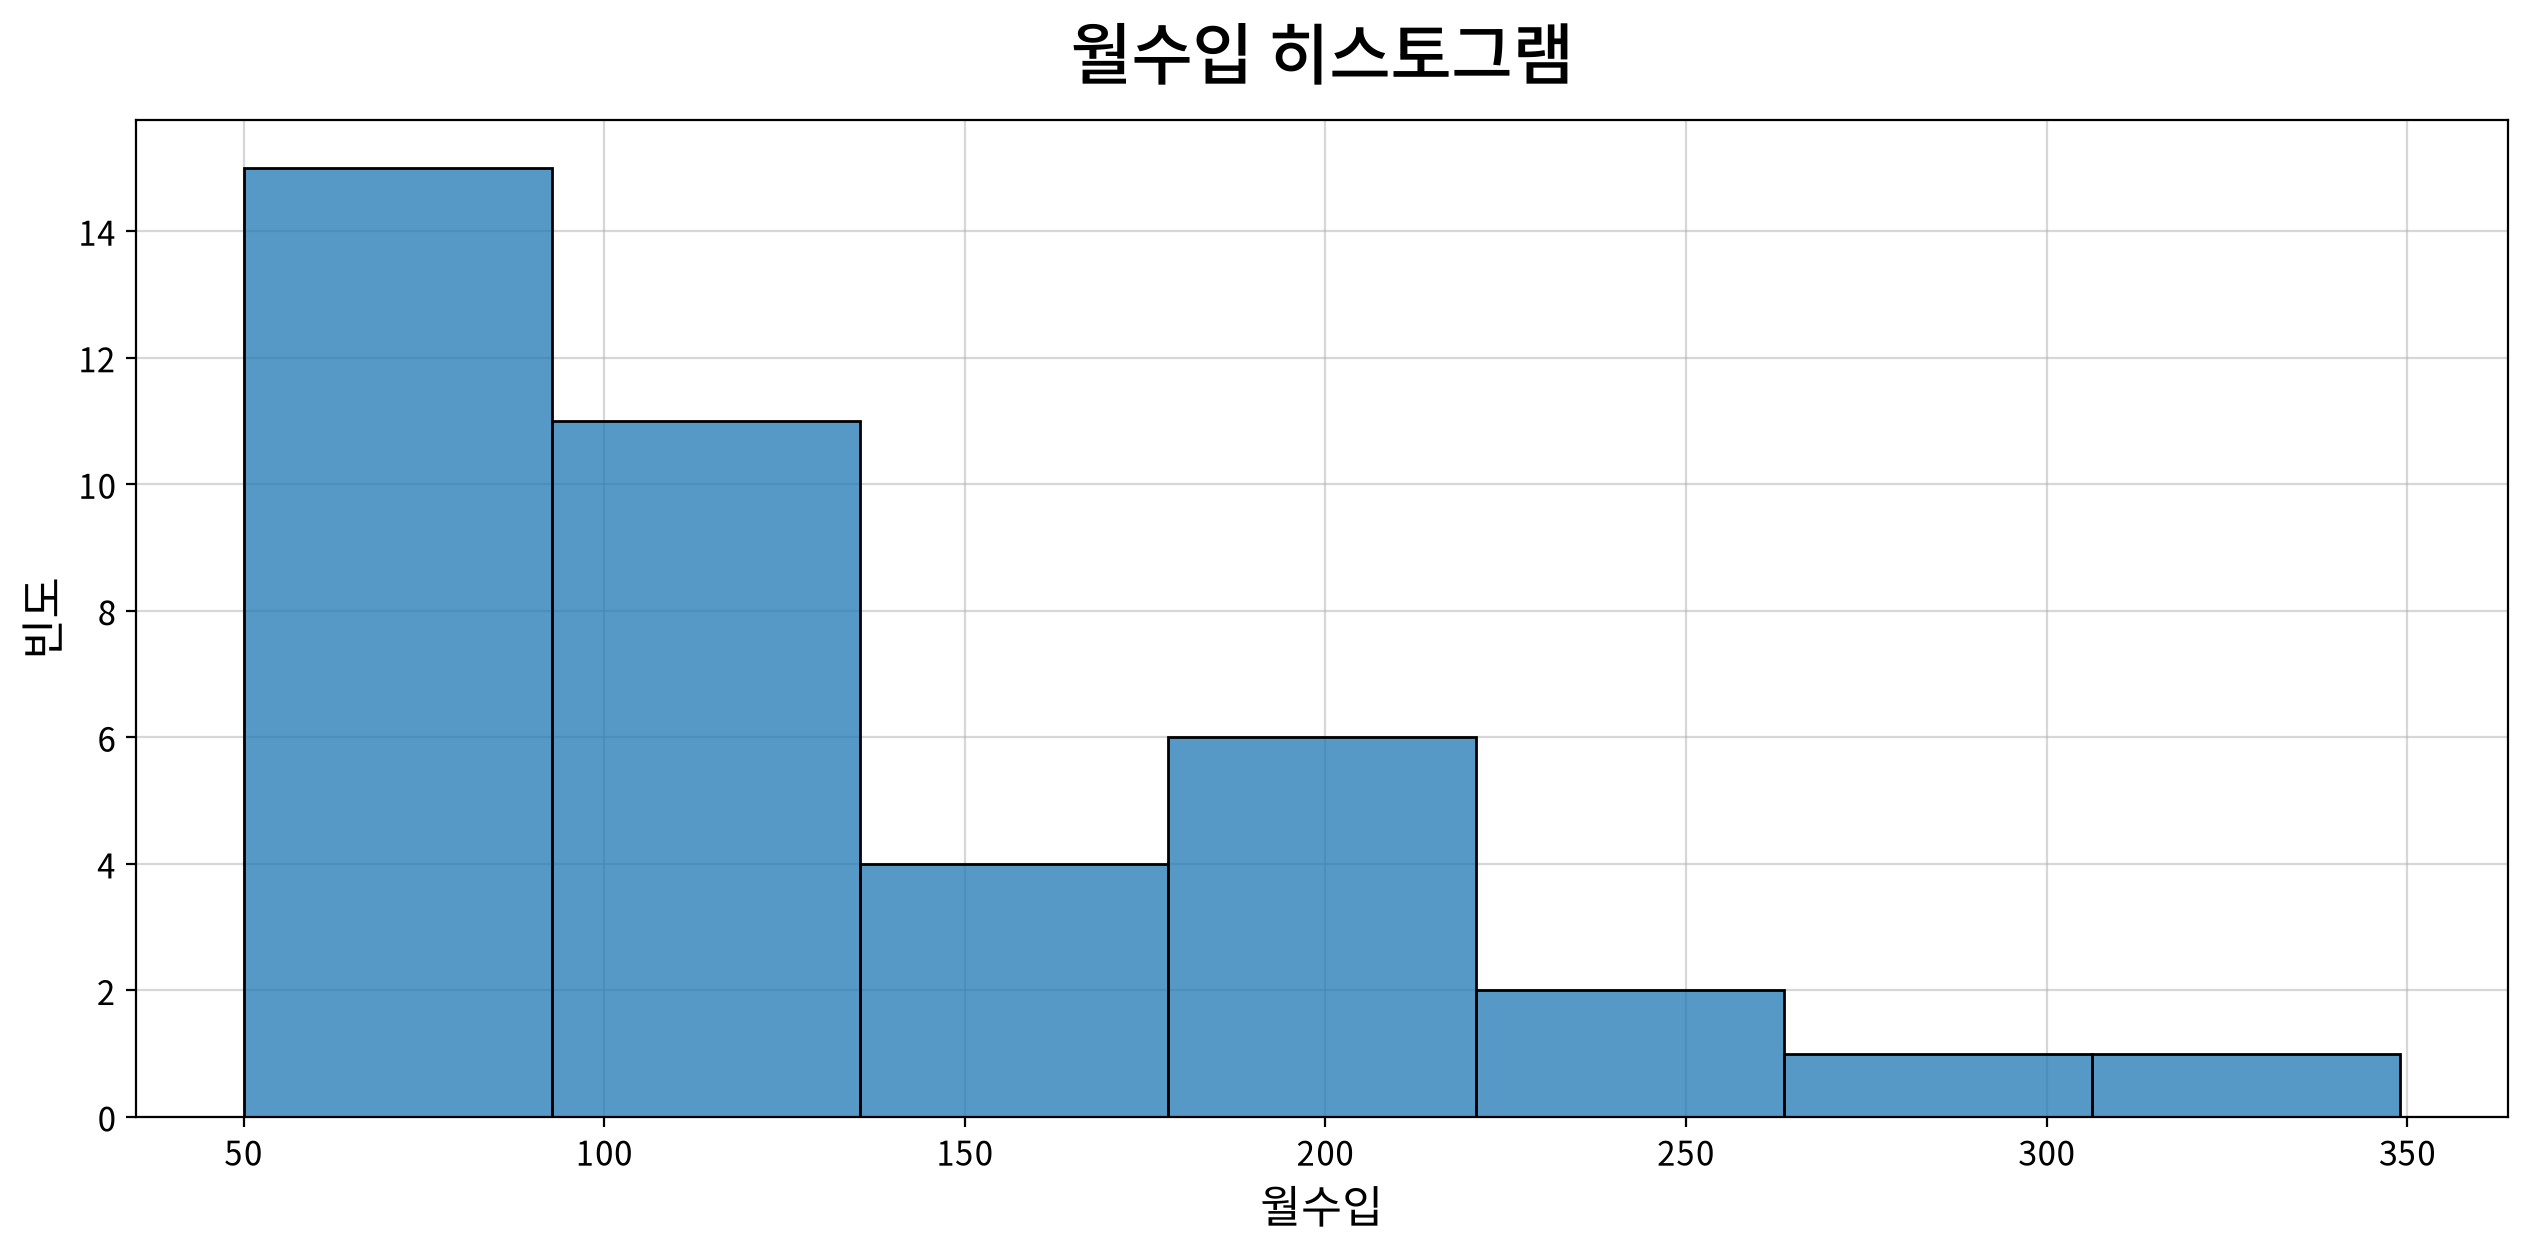

In [13]:
fig, ax = my_plot.init(title='월수입 히스토그램',
                       xlabel='월수입', ylabel='빈도')

# 패턴1 - 자동인식 패턴
# sb.histplot(data=origin['월수입'])
# 패턴2 - 개별 데이터 직접 지정 패턴
# sb.histplot(x=origin['월수입'])
# 패턴3 - DataFrame + 컬럼명 패턴
sb.histplot(data=origin, x='월수입')

my_plot.show()

### #03 히스토그램의 구간 설정

1. Numpy를 통해 정확한 구간경계 얻기

In [14]:
hist, bins = np.histogram(origin['월수입'], bins=5)
# 소수점 첫째자리까지 남기고 반올림
bins = np.round(bins, 1)
print("값:", hist)
print("구간:", bins)

값: [20  9  7  2  2]
구간: [ 50.  109.8 169.6 229.4 289.2 349. ]


2. Numpy를 통해 정확한 구간경계를 히스토그램에 적용

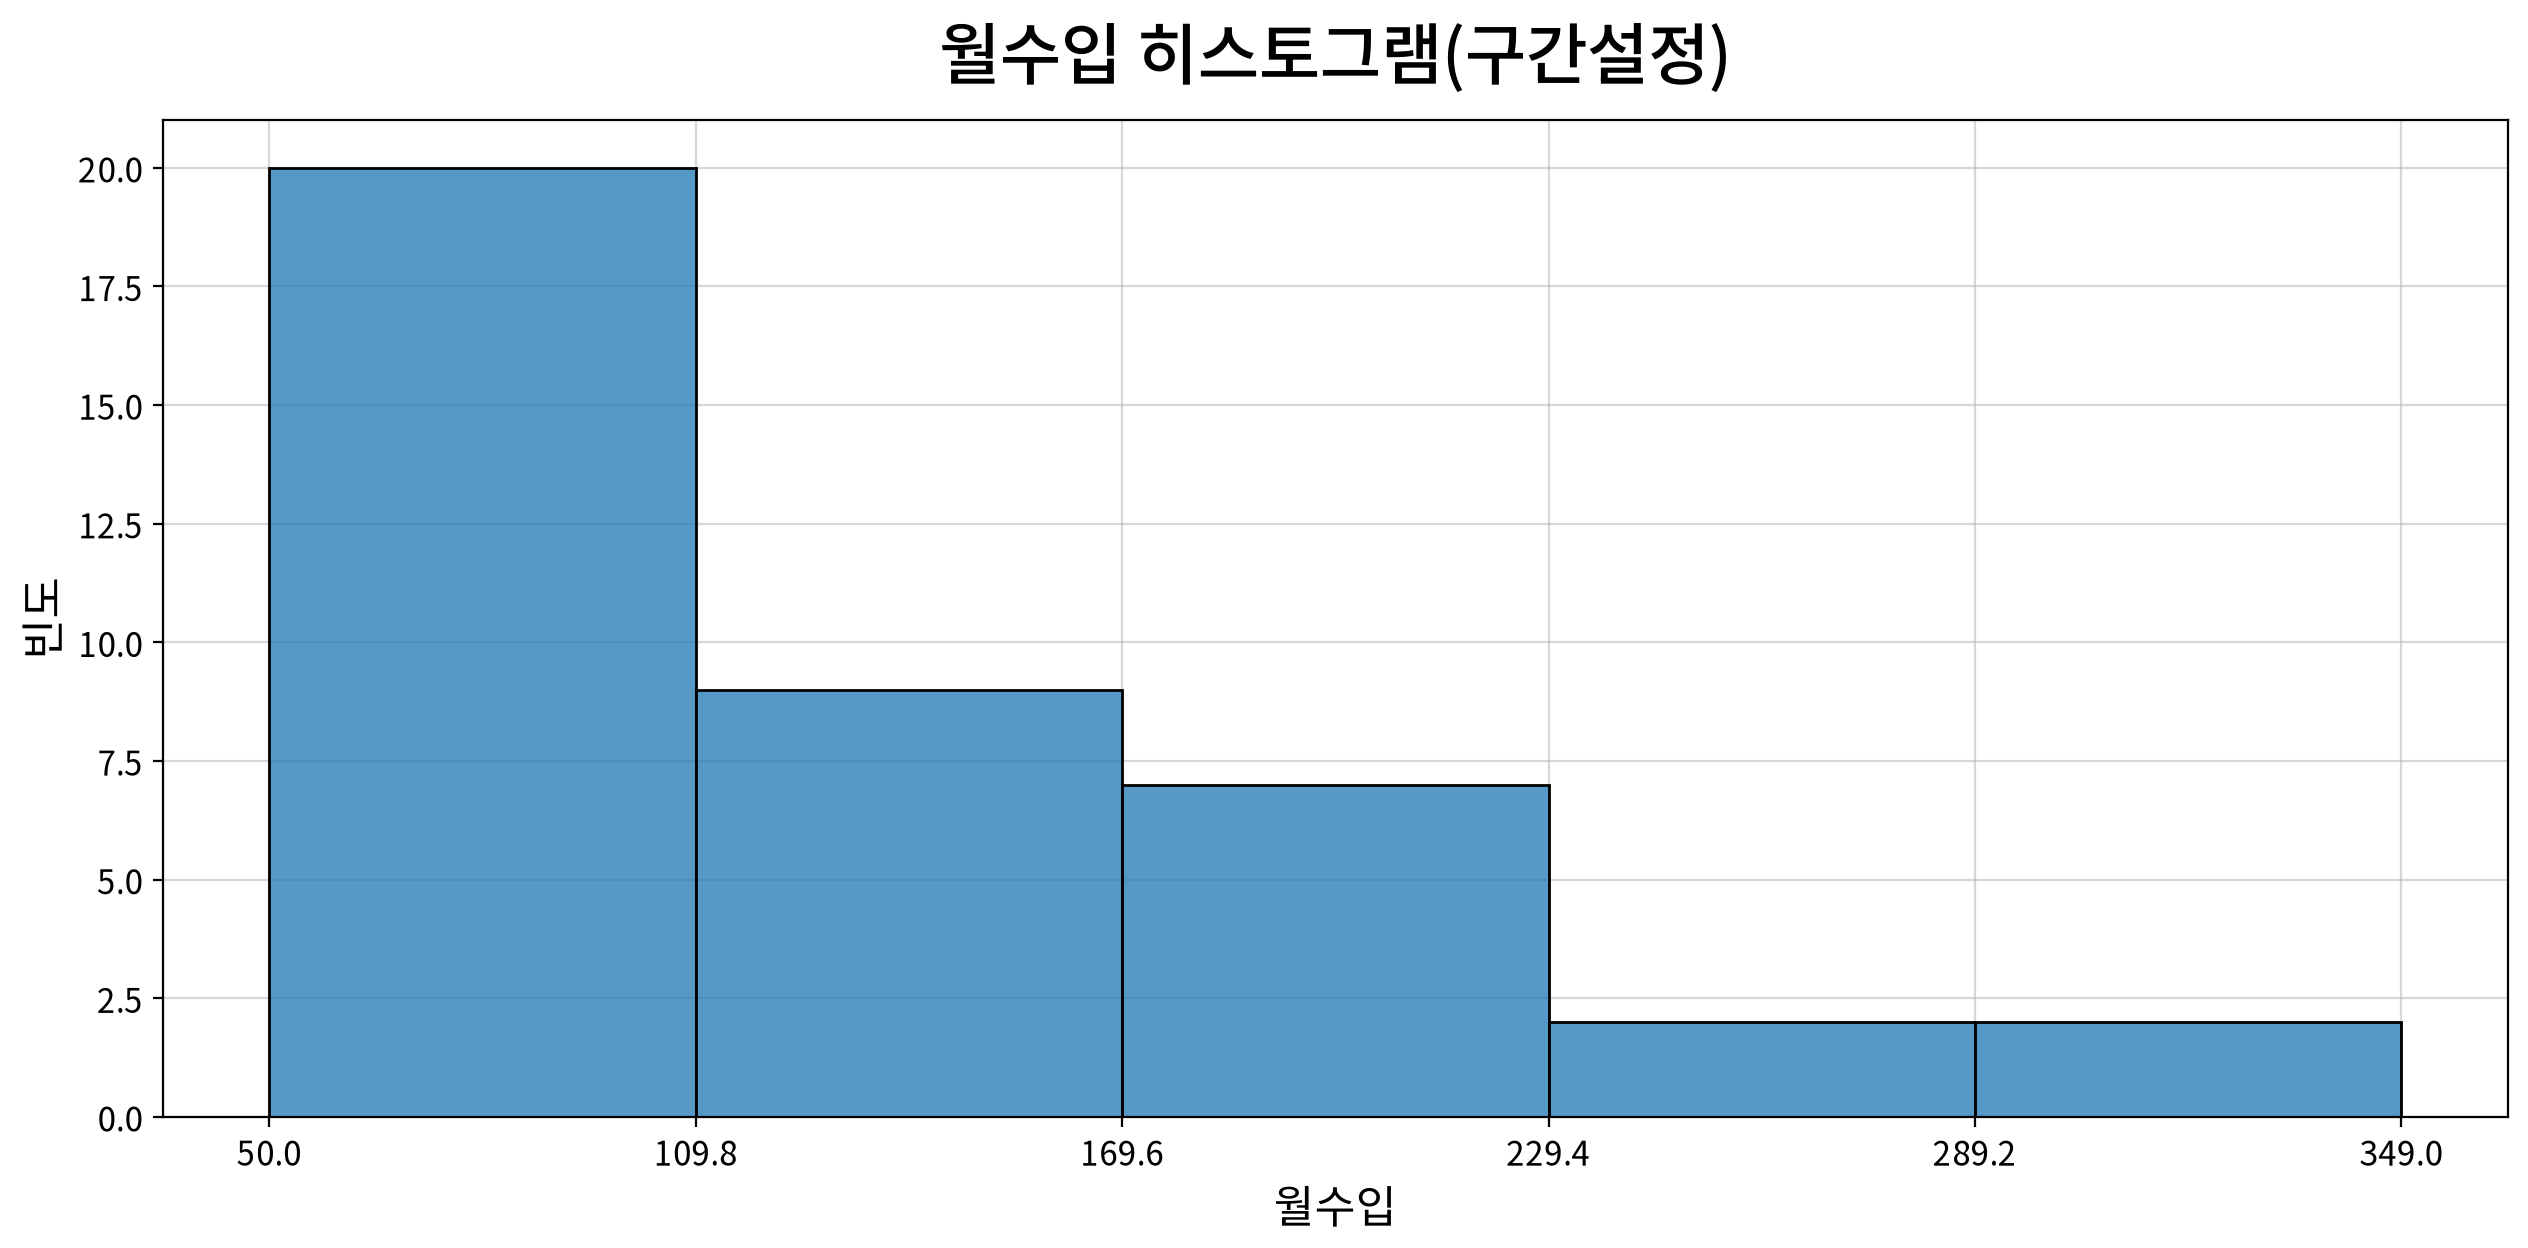

In [15]:
fig, ax = my_plot.init(title='월수입 히스토그램(구간설정)',
                       xlabel='월수입', ylabel='빈도')

# 구간을 설정한 히스토그램
# -> bins는 이전 코드 블록에서 생성한 정보
sb.histplot(data=origin, x='월수입', bins=bins)

# x축 좌표에 구간값 표시하기
ax.set_xticks(bins, bins)

my_plot.show()

> 인사이트
- 월수입의 범위는 약 50 ~ 349 사이에 분포한다.
- 50 ~ 109.8 구간에 가장 많은 직원이 분포해 있으며, 20명으로 전체의 절반이다.
- 월수입이 증가할 수록 해당 구간의 도수(인원 수)는 감소하는 경향을 보인다.
- 전체 분포는 낮은 월수입 구간에 관측치가 집중되어 있고, 높은 월수입 구간에는 소수만 존재한다.
- 고소득 구간(229.4 이상)에 속한 직원은 전체의 10%(4명)에 속한다.

### #04 히스토그램의 옵션 설정

1. 커널밀도와 함께 표시하기

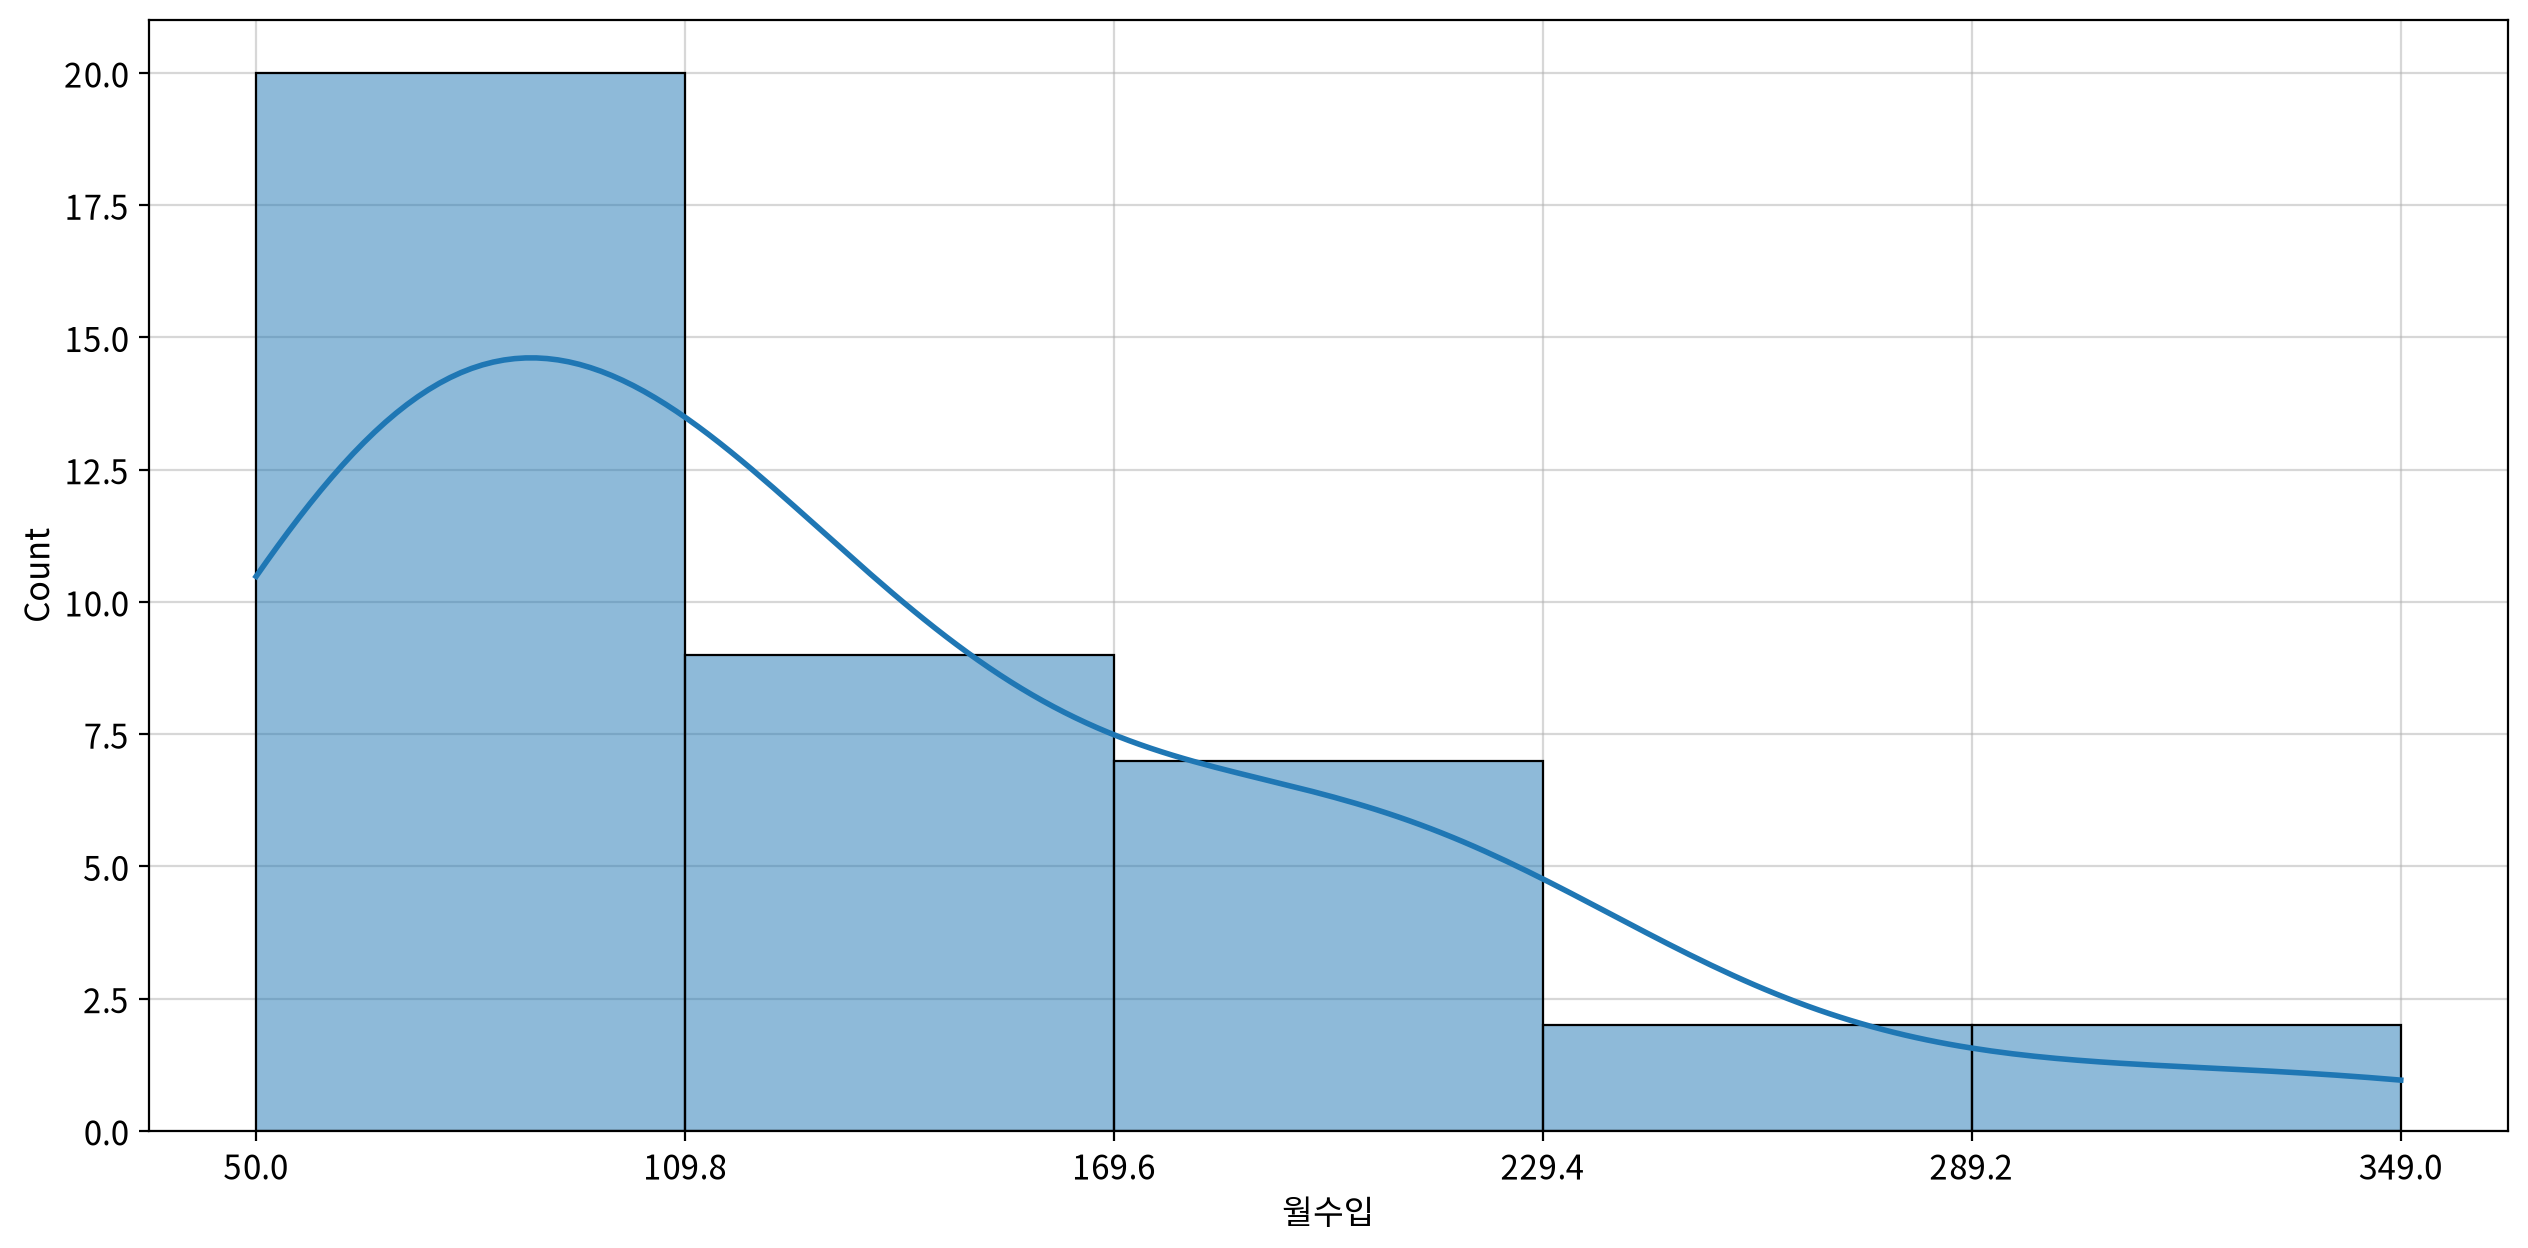

In [16]:
# 그래프 초기화
fig, ax = my_plot.init()

# 구간을 설정한 히스토그램 -> bins는 이전 코드 블록에서 생성한 정보
sb.histplot(data=origin, x='월수입', bins=bins, kde=True, linewidth=0.8)

# x축 좌표에 구간값 표시하기
ax.set_xticks(bins, bins)

# 출력
my_plot.show()

2. 범주 구분, 선 색상 / 굵기 설정하기

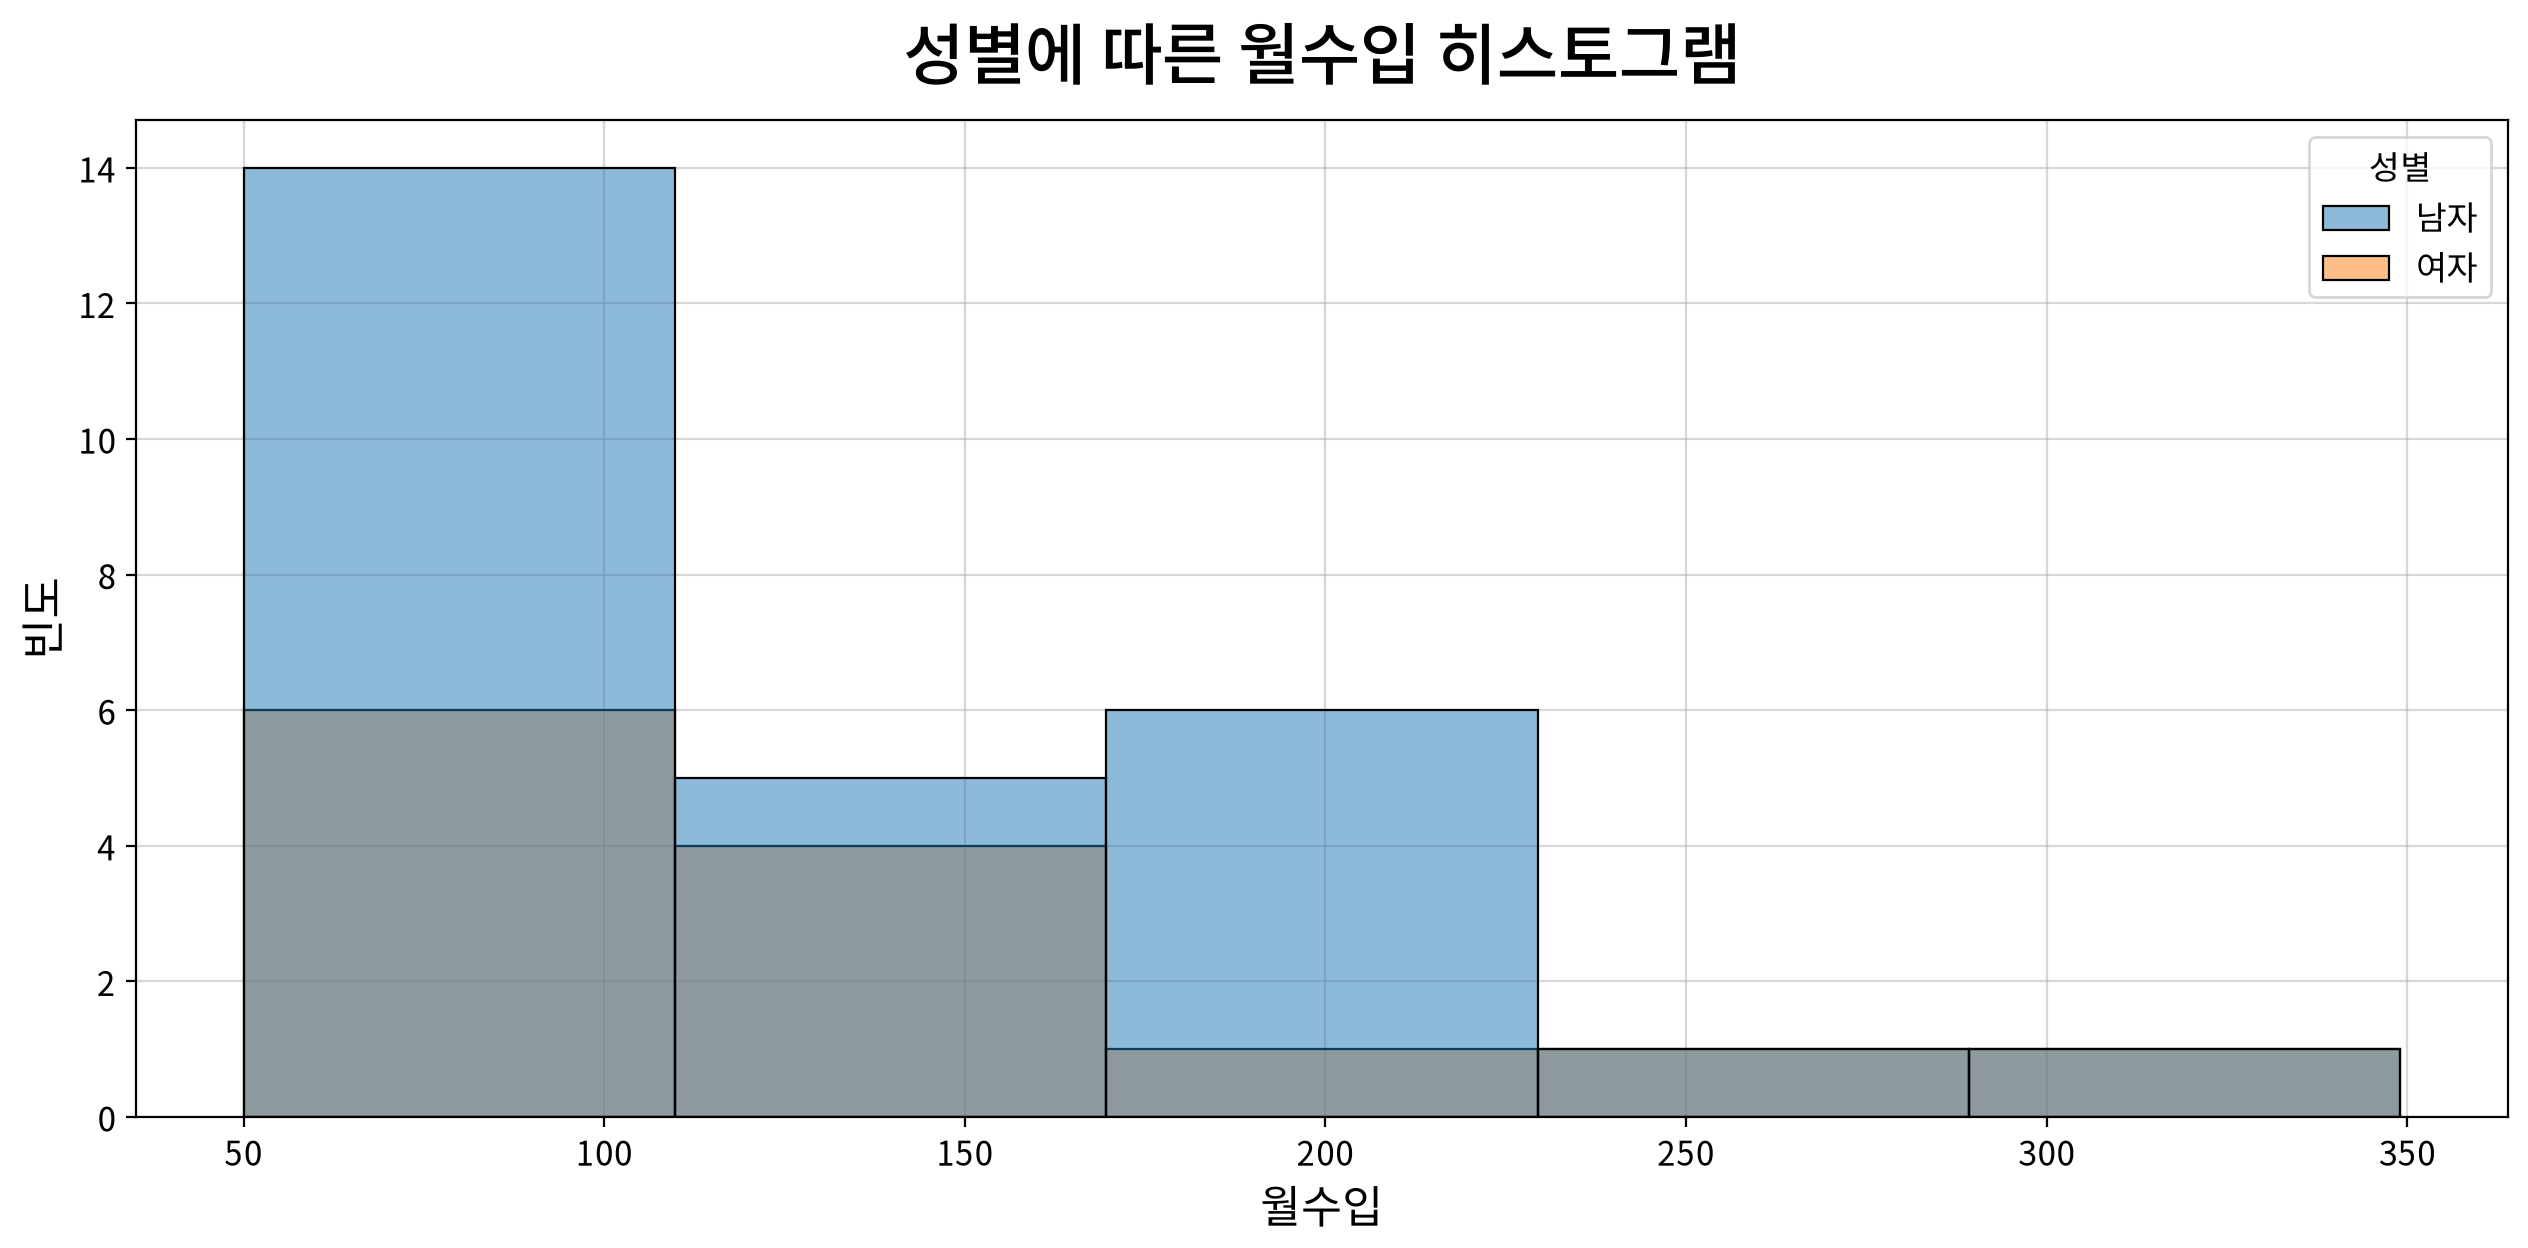

In [17]:
# 그래프 초기화
fig, ax = my_plot.init(title='성별에 따른 월수입 히스토그램',
                       xlabel='월수입', ylabel='빈도')

# 구간을 설정한 히스토그램 -> bins는 이전 코드 블록에서 생성한 정보
sb.histplot(data=origin, x='월수입', hue= '성별', bins=bins,
            edgecolor="#000000", linewidth=0.8)

# 출력
my_plot.show()

> 인사이트
- 남성 직원 수가 여성보다 많다.
- 남성의 월수입 분포가 여성보다 더 넓은 범위를 가진다.
- 남녀 모두 저소득 구간(약 50 ~ 110)에 가장 많은 인원이 집중되어 있다.

### #05 모듈화 기능 확인

1. 히스토그램 모듈 사용하기

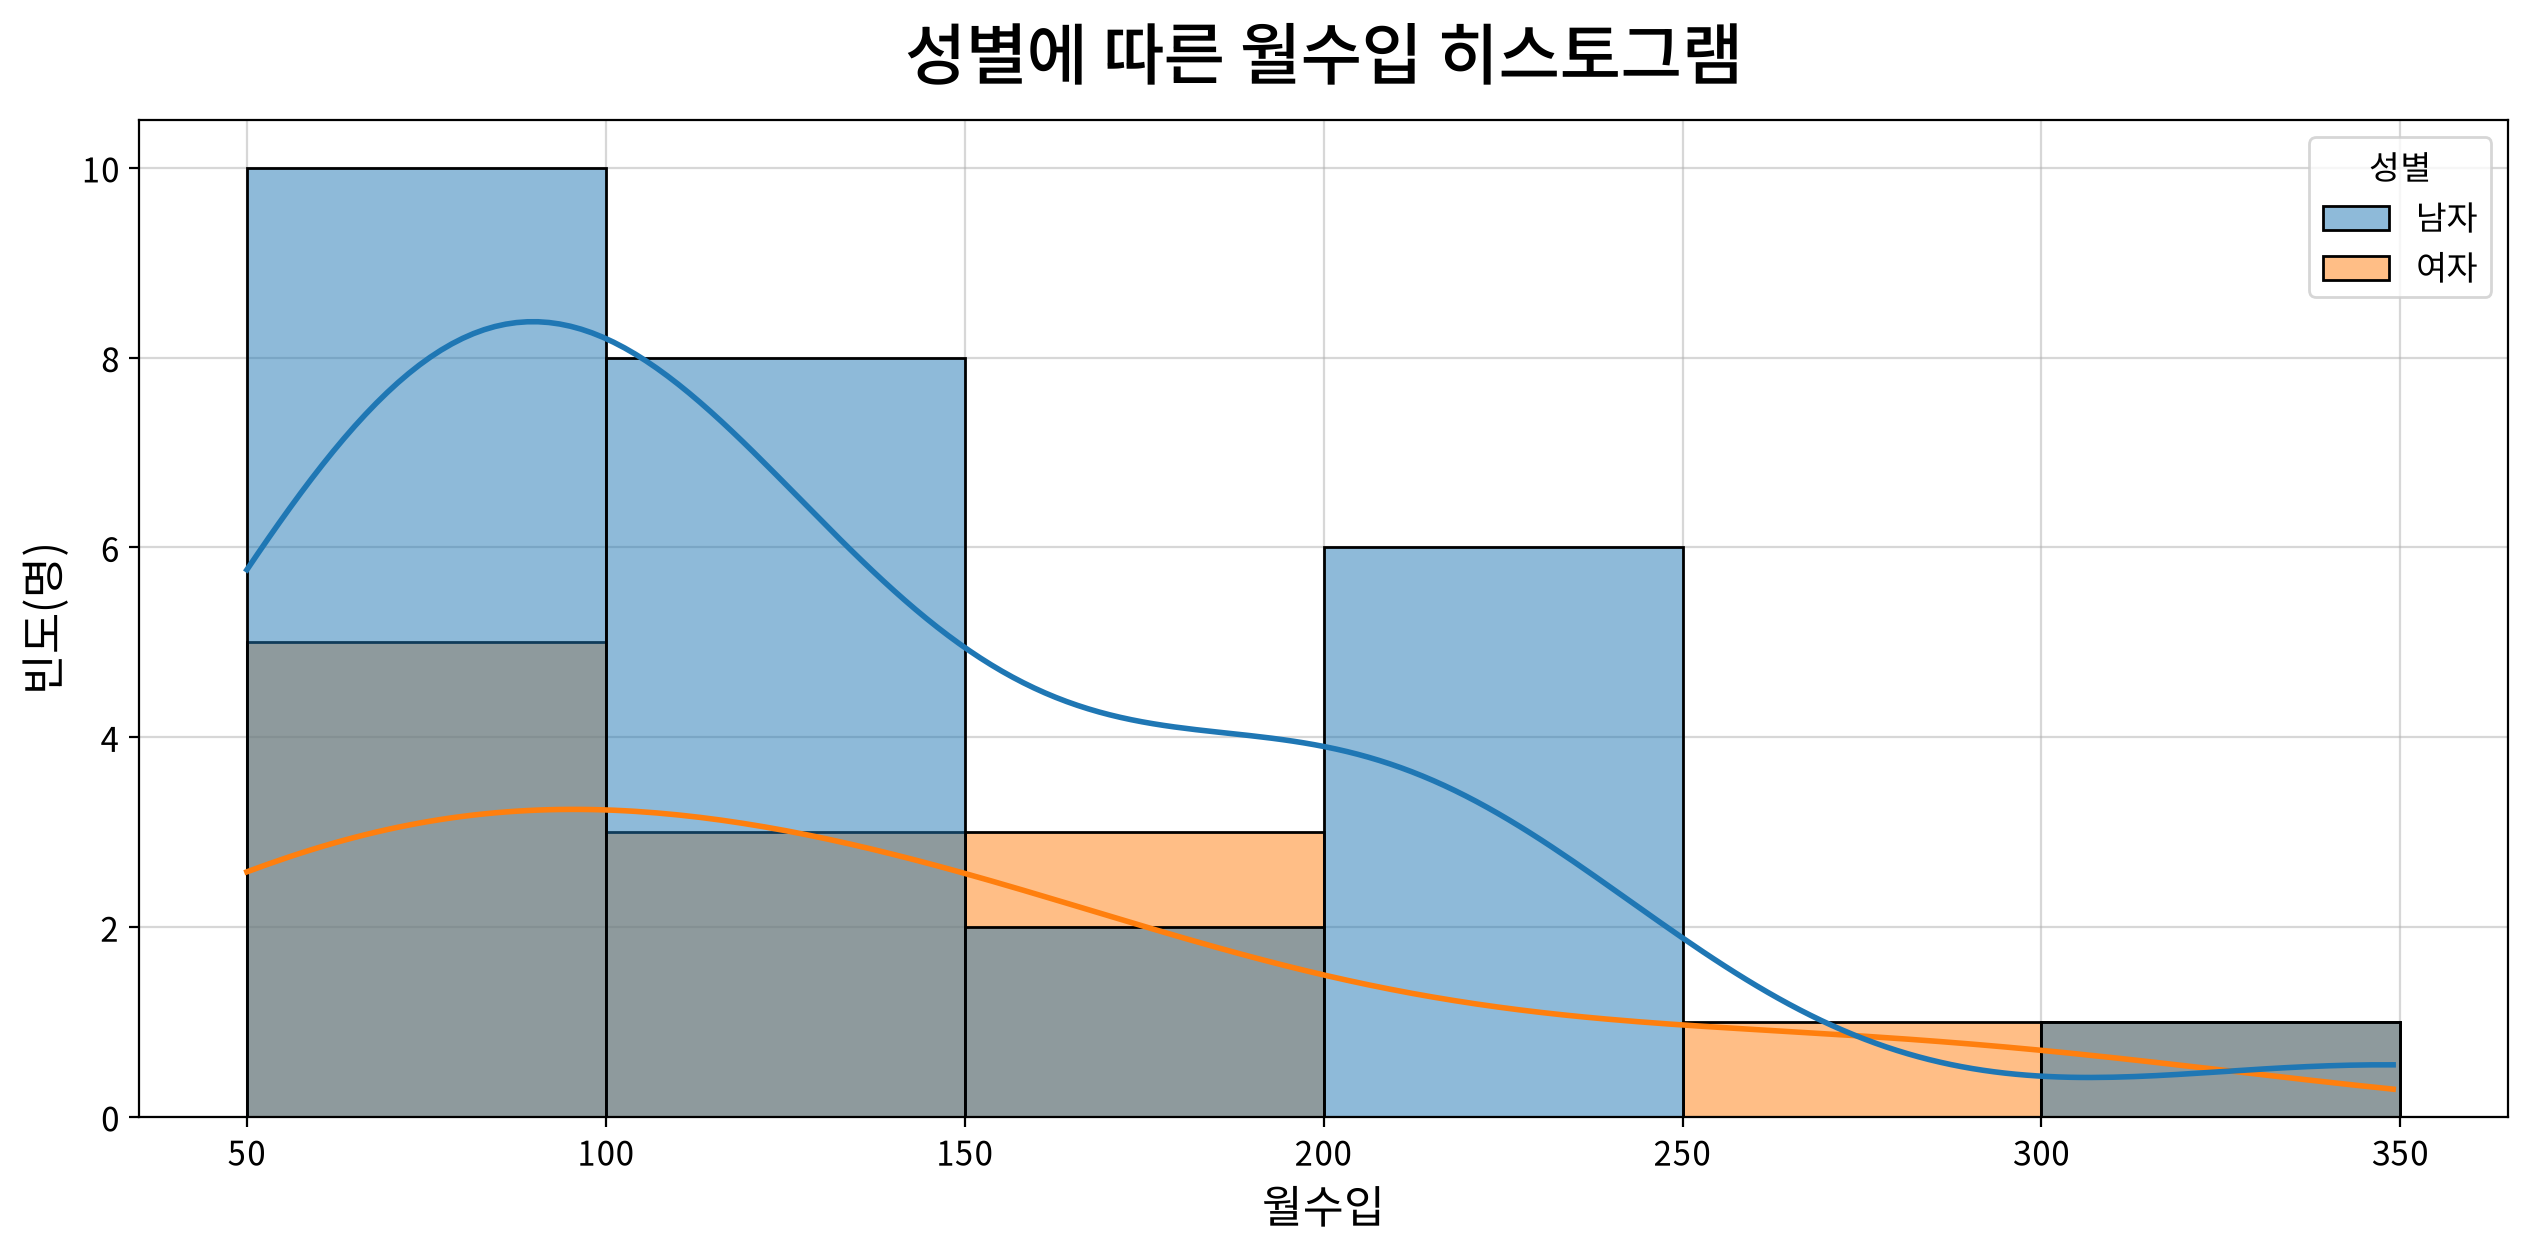

In [19]:
my_plot.histplot(data=origin, x='월수입', hue='성별',
                bins=[50, 100, 150, 200, 250, 300, 350], kde=True,
                title='성별에 따른 월수입 히스토그램',
                xlabel='월수입', ylabel='빈도(명)')

---

## 연습문제

### 두 학과의 성적 분포 비교

In [ ]:
# 라이브러리 참조
from jussam import load_data
from helpers import *
import seaborn as sb
import numpy as np

In [21]:
# 데이터 가져오기
origin = load_data('stat_comp_grade')
origin.head()

📚 통계학 전공(STAT) 학생과 전산학 전공(COMP) 학생의 통계학 과목에 대한 중간고사 성적과 기말시험 성적 (출처: 방송통신대학교 통계학개론 수업내용에서 발췌)


,전공,중간고사,기말고사
0,STAT,34,86
1,STAT,50,77
2,STAT,75,74
3,COMP,76,96
4,COMP,61,78


In [22]:
# 통계학 전공 학생의 중간고사 성적 분포
df1 = origin[origin['전공'] == 'STAT']
df1

,전공,중간고사,기말고사
0,STAT,34,86
1,STAT,50,77
2,STAT,75,74
7,STAT,47,57
8,STAT,94,82
10,STAT,38,53
11,STAT,65,70
12,STAT,47,60
13,STAT,88,95
16,STAT,92,95


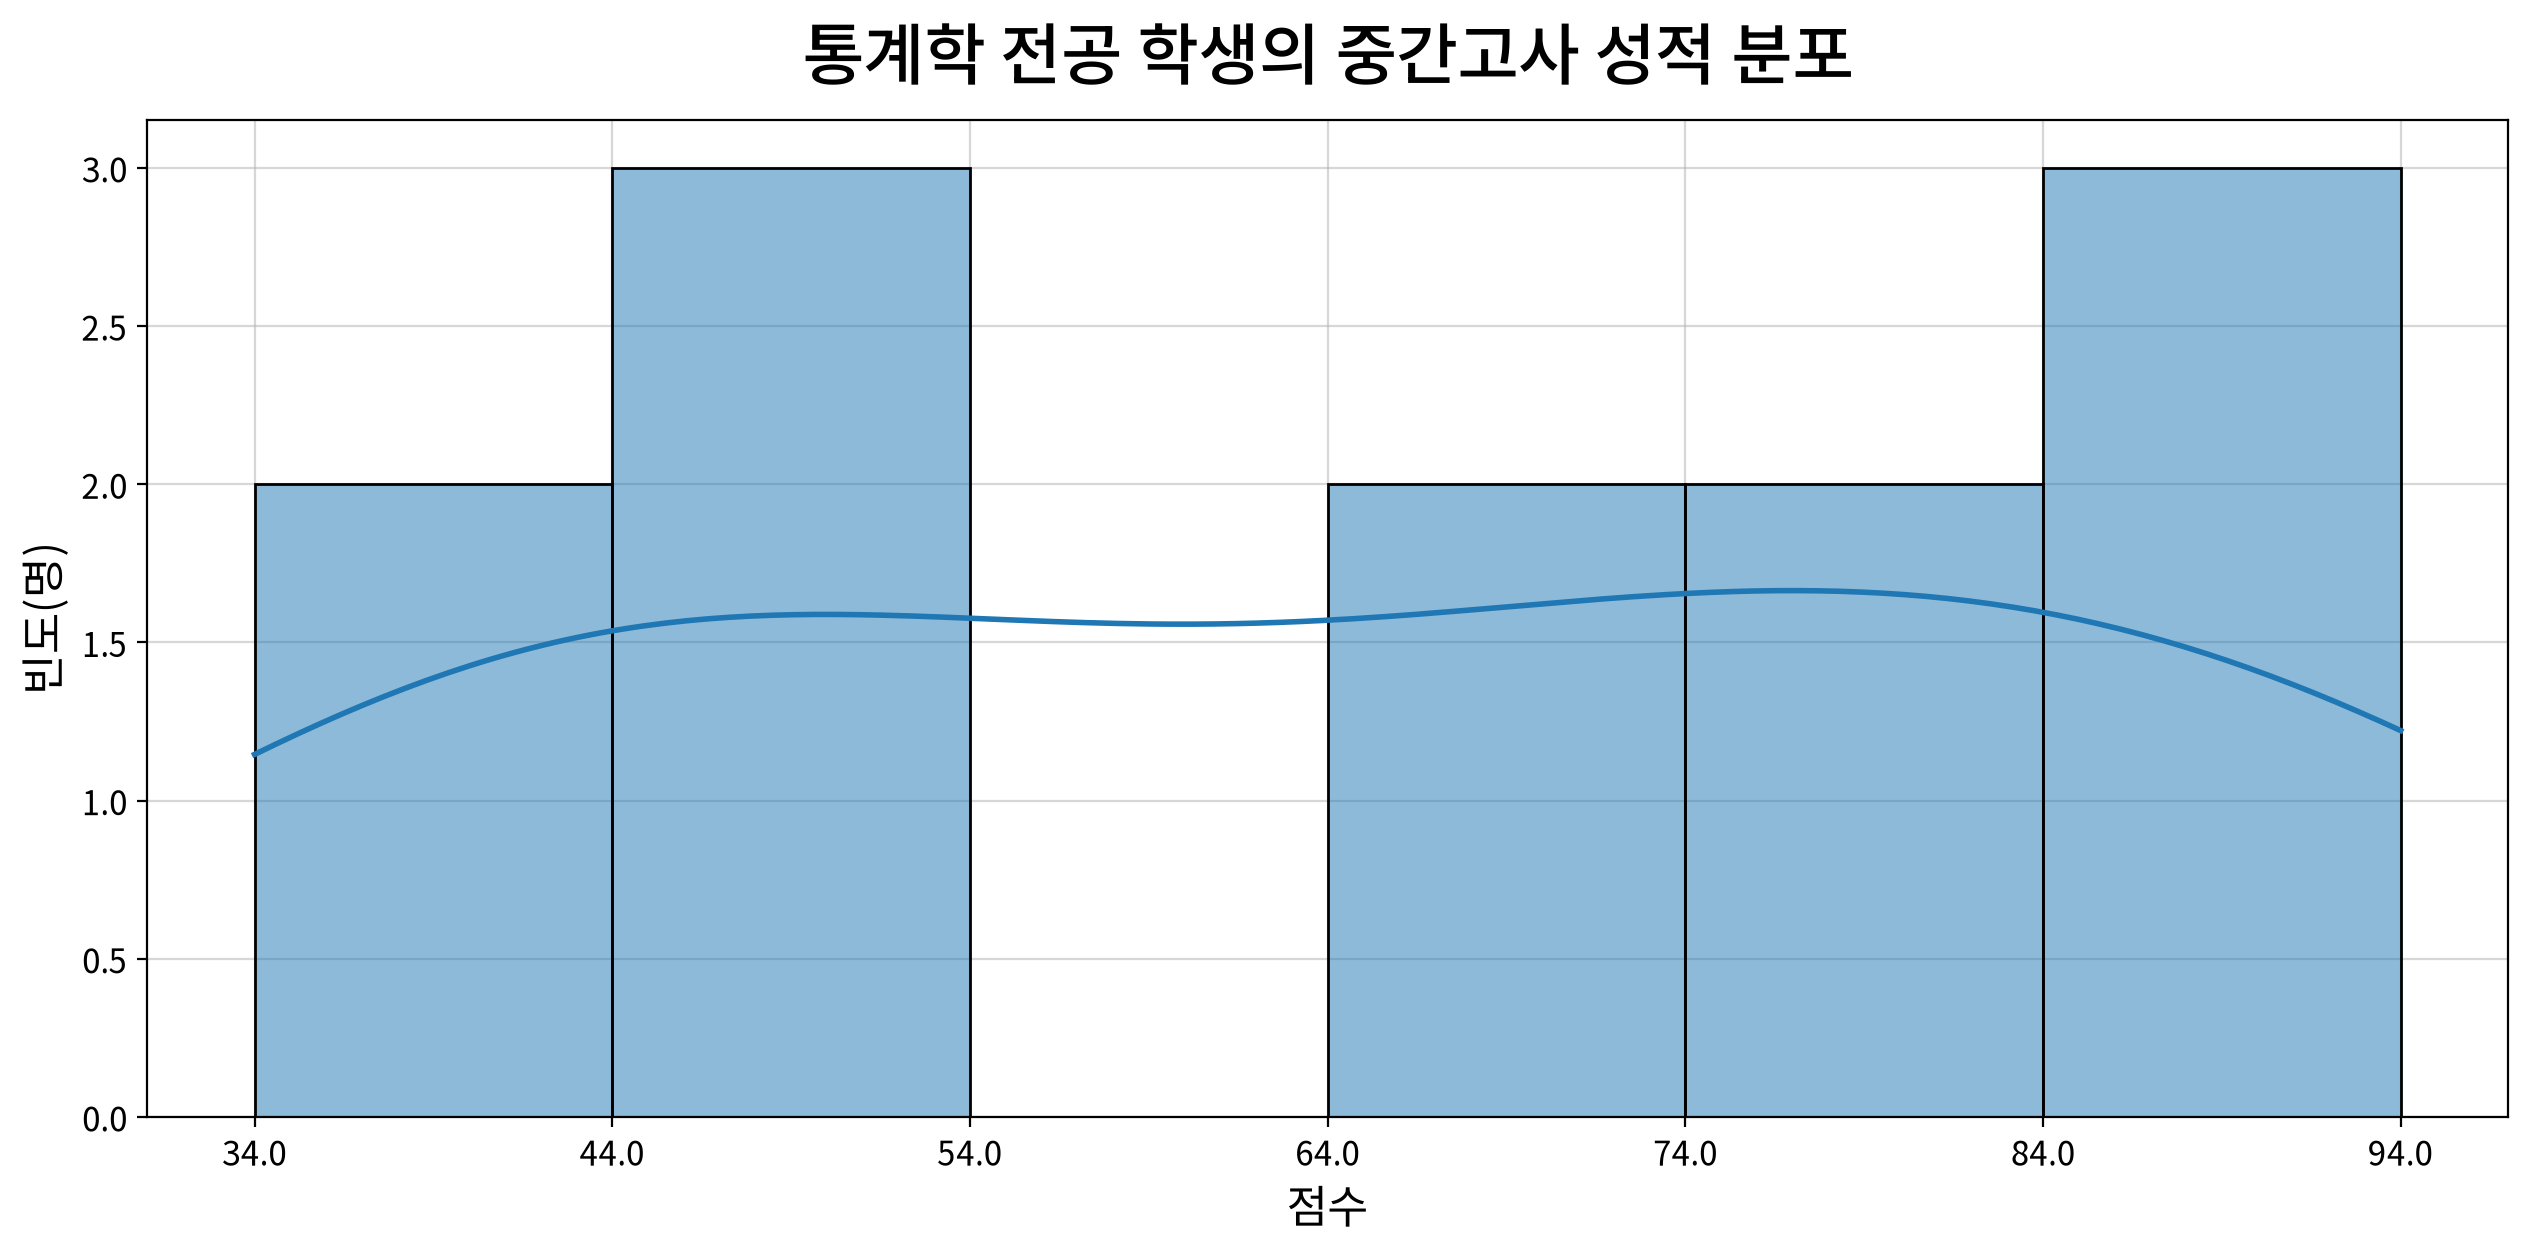

In [25]:
# 통계학 중간고사 히스토그램 시각화 하기
my_plot.histplot(data=df1, 
                 x='중간고사', bins=6, kde=True,
                 title='통계학 전공 학생의 중간고사 성적 분포', 
                 xlabel='점수', ylabel='빈도(명)')

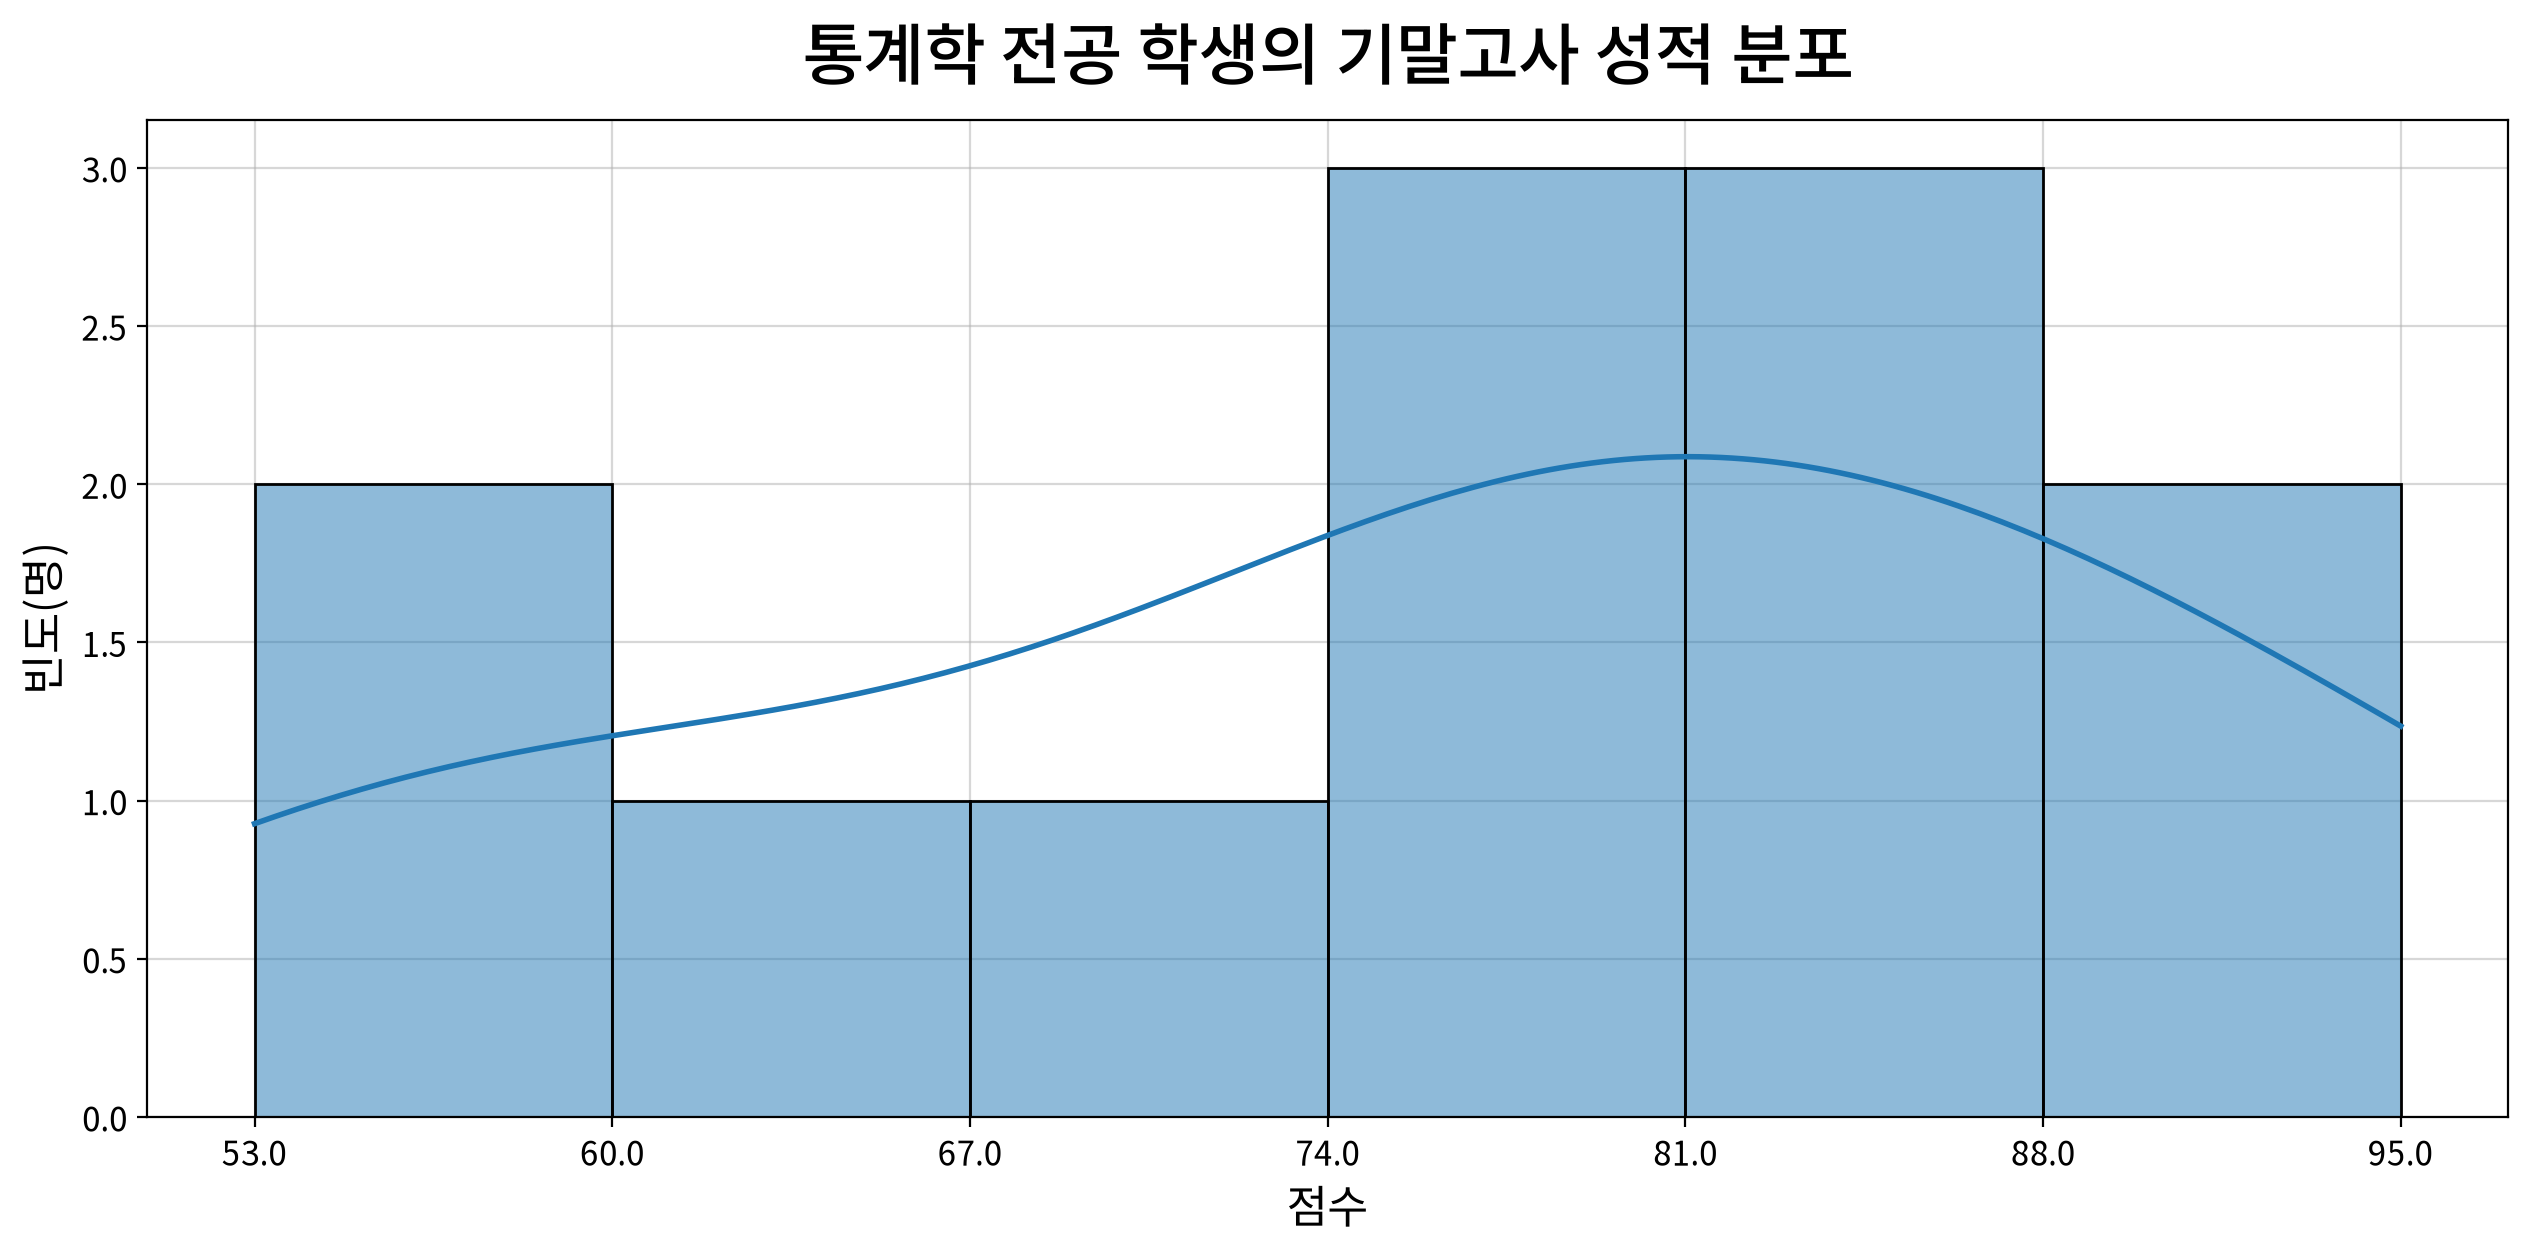

In [26]:
# 통계학 기말고사 히스토그램 시각화 하기
my_plot.histplot(data=df1, 
                 x='기말고사', bins=6, kde=True,
                 title='통계학 전공 학생의 기말고사 성적 분포', 
                 xlabel='점수', ylabel='빈도(명)')

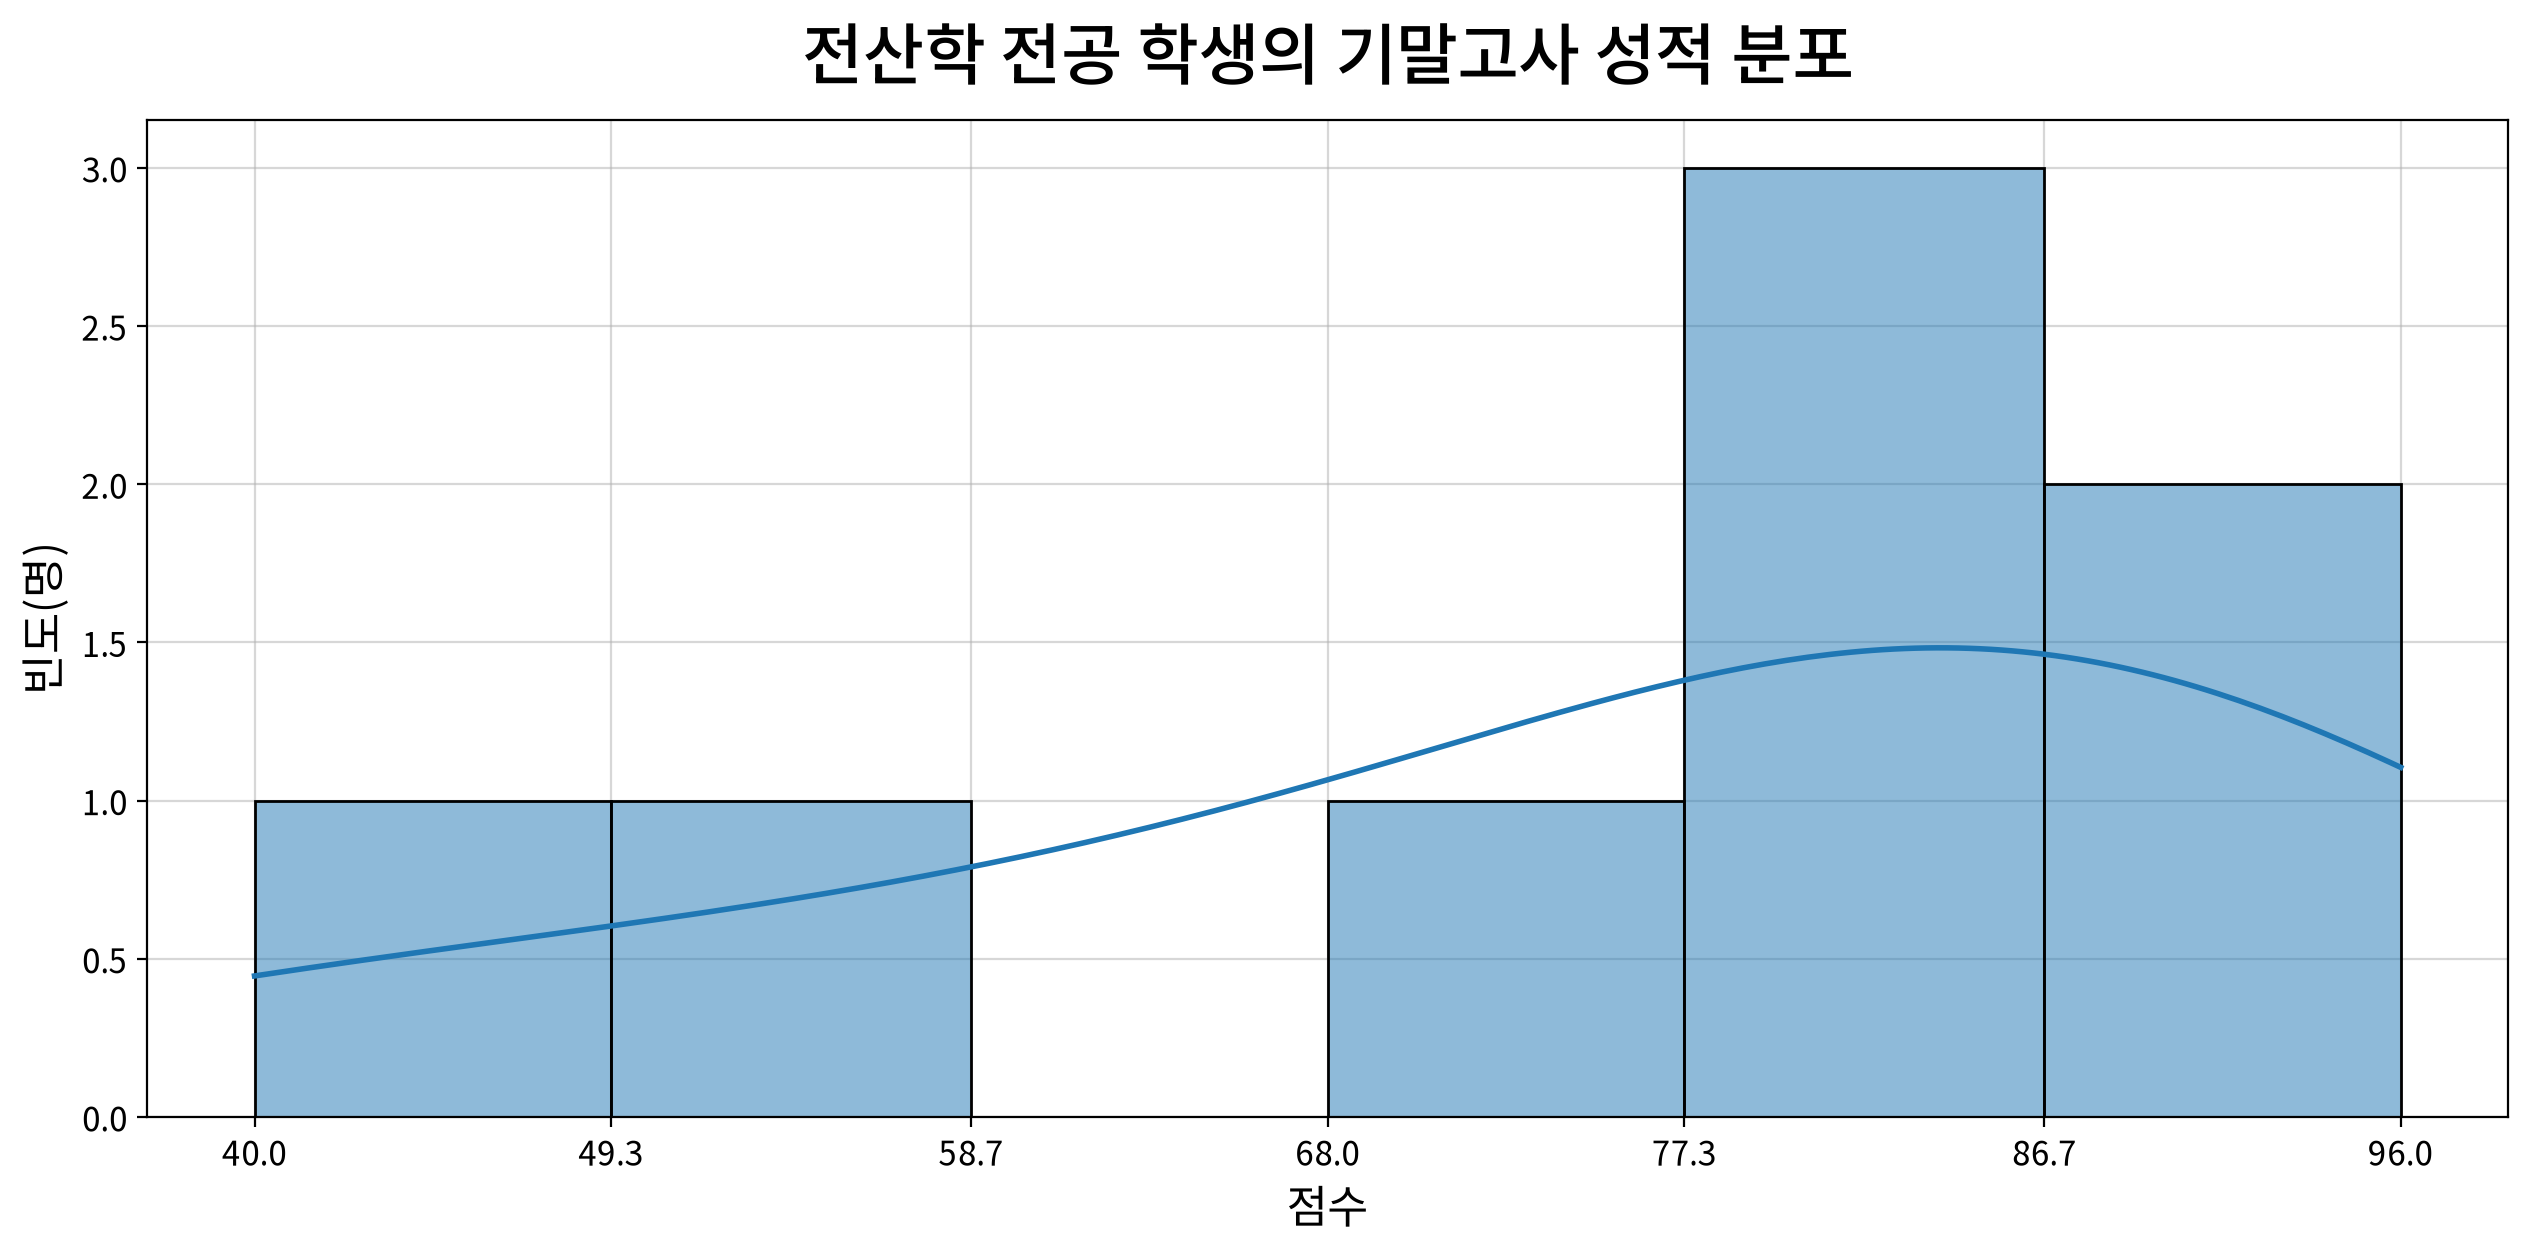

In [28]:
# 전산학 기말고사 히스토그램 시각화 하기
my_plot.histplot(data=origin[origin['전공'] == 'COMP'], 
                 x='기말고사', bins=6, kde=True,
                 title='전산학 전공 학생의 기말고사 성적 분포', 
                 xlabel='점수', ylabel='빈도(명)')

> 문제 답변
- 통계학 전공의 중간고사 점수 분포에 나타난 봉우리는 2개이다.
- 통계학 전공의 중간고사 분포에서 학생 수가 0명인 점수 구간은 54~64 이다.
- 통계학 전공 학생들의 기말고사에서 가장 많은 학생이 분포한 점수 구간은 74 ~ 88 이다.
- 전산학 전공의 기말고사 점수 분포는 음의 왜도이다.
- 두 전공의 중간고사와 기말고사를 비교했을 때, 학생들의 점수는 전반적으로 높아졌다.